# Clase 8 · Laboratorio — Modelos Avanzados: Ensambles y Redes Neuronales

**Duración:** 90 minutos  
**Modalidad:** trabajo en dupla o individual  
**Dataset:** Saber 11 real (500k filas)

**Objetivo:** practicar Random Forest, Gradient Boosting, MLP; comparar hiperparámetros; y crear una tabla final de TODOS los modelos del curso.

**Entrega:** subir notebook ejecutado a Moodle antes del jueves.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay,
                              mean_squared_error, r2_score)
import warnings; warnings.filterwarnings('ignore')

df = pd.read_csv("saber11_muestra_500k.csv")
df["ESTRATO_NUM"] = df["FAMI_ESTRATOVIVIENDA"].str.extract(r"(\d+)").astype(float)

print(f"Dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Dataset: 500,000 filas x 52 columnas


---
## Tarea 1 (20 min) — RF vs GB: predecir COLE_AREA_UBICACION

**Problema:** predecir si un colegio es RURAL (1) o URBANO (0) usando features socioeconómicas.

### 1.1 Preparar datos

In [2]:
# Target binario: RURAL=1, URBANO=0
df_t1 = df[["COLE_AREA_UBICACION","COLE_NATURALEZA","COLE_JORNADA","COLE_BILINGUE",
            "ESTU_GENERO","FAMI_TIENEINTERNET","FAMI_TIENECOMPUTADOR","ESTRATO_NUM"]].dropna()

df_t1["target"] = (df_t1["COLE_AREA_UBICACION"] == "RURAL").astype(int)

# OneHot de features categóricas (sin incluir target ni COLE_AREA_UBICACION)
features_cat = ["COLE_NATURALEZA","COLE_JORNADA","COLE_BILINGUE","ESTU_GENERO",
                "FAMI_TIENEINTERNET","FAMI_TIENECOMPUTADOR"]
df_t1_enc = pd.get_dummies(df_t1[features_cat + ["ESTRATO_NUM","target"]], 
                            columns=features_cat, drop_first=True, dtype=int)

X_t1 = df_t1_enc.drop("target", axis=1)
y_t1 = df_t1_enc["target"]

X_train_t1, X_test_t1, y_train_t1, y_test_t1 = train_test_split(
    X_t1, y_t1, test_size=0.2, random_state=42, stratify=y_t1
)

print(f"Train: {len(X_train_t1):,} | Test: {len(X_test_t1):,}")
print(f"Distribución target: {y_train_t1.value_counts().to_dict()}")

Train: 294,060 | Test: 73,516
Distribución target: {0: 255978, 1: 38082}


### 1.2 Entrenar Random Forest y Gradient Boosting

In [3]:
# Random Forest
rf_t1 = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
rf_t1.fit(X_train_t1, y_train_t1)
pred_rf_t1 = rf_t1.predict(X_test_t1)
acc_rf_t1 = accuracy_score(y_test_t1, pred_rf_t1)
f1_rf_t1  = f1_score(y_test_t1, pred_rf_t1, average="binary")

# Gradient Boosting
gb_t1 = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, random_state=42)
gb_t1.fit(X_train_t1, y_train_t1)
pred_gb_t1 = gb_t1.predict(X_test_t1)
acc_gb_t1 = accuracy_score(y_test_t1, pred_gb_t1)
f1_gb_t1  = f1_score(y_test_t1, pred_gb_t1, average="binary")

print("=== Tarea 1: Predecir RURAL vs URBANO ===")
print(f"Random Forest     → Accuracy: {acc_rf_t1:.4f} | F1: {f1_rf_t1:.4f}")
print(f"Gradient Boosting → Accuracy: {acc_gb_t1:.4f} | F1: {f1_gb_t1:.4f}")
print(f"\nGanador: {'Random Forest' if f1_rf_t1 > f1_gb_t1 else 'Gradient Boosting'}")

=== Tarea 1: Predecir RURAL vs URBANO ===
Random Forest     → Accuracy: 0.8705 | F1: 0.0002
Gradient Boosting → Accuracy: 0.8707 | F1: 0.0270

Ganador: Gradient Boosting


### 1.3 Matrices de confusión y feature importance

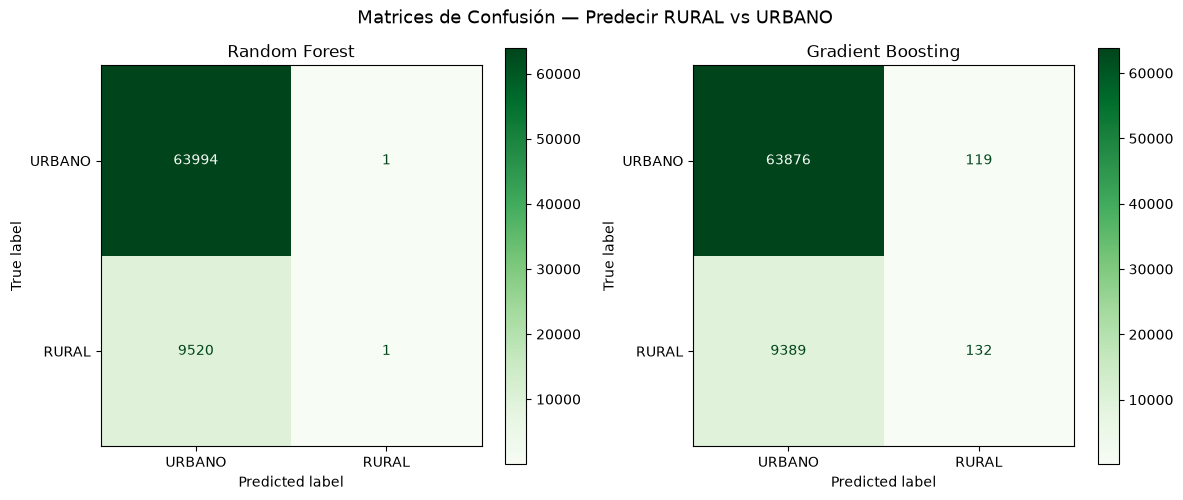

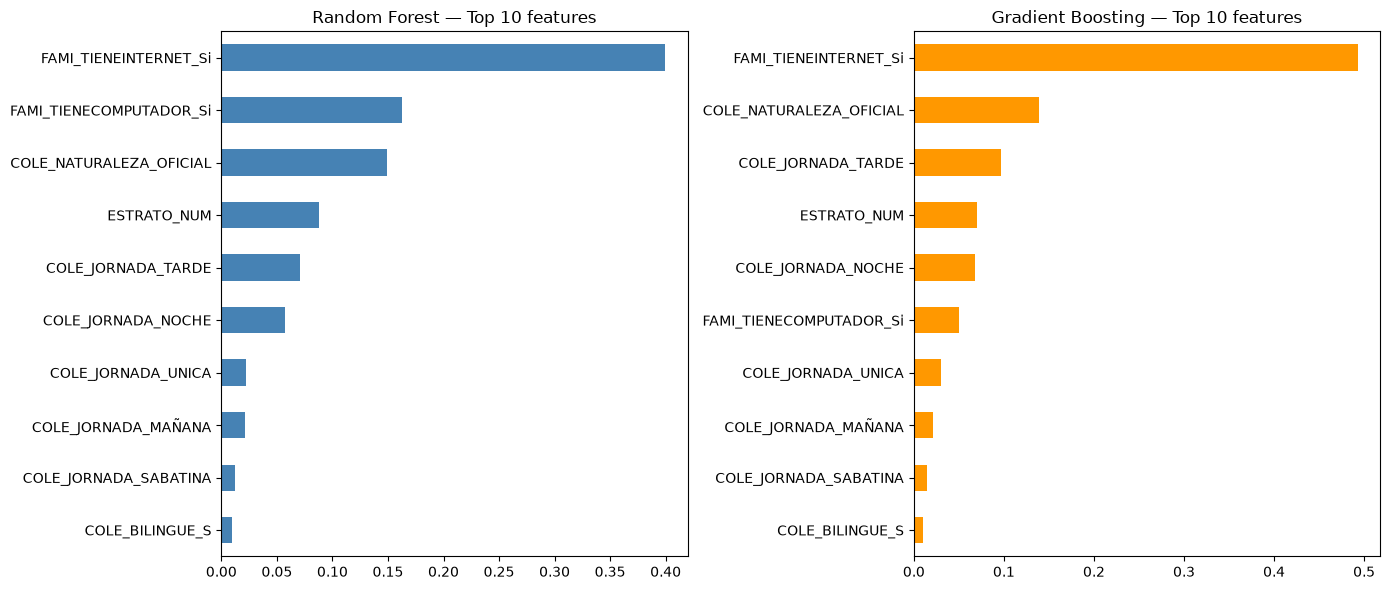

In [4]:
# Matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, preds) in zip(axes, [("Random Forest", pred_rf_t1), ("Gradient Boosting", pred_gb_t1)]):
    ConfusionMatrixDisplay.from_predictions(y_test_t1, preds, ax=ax, 
        display_labels=["URBANO", "RURAL"], cmap="Greens")
    ax.set_title(nombre)
plt.suptitle("Matrices de Confusión — Predecir RURAL vs URBANO", fontsize=13)
plt.tight_layout(); plt.show()

# Feature importance
feat_rf = pd.Series(rf_t1.feature_importances_, index=X_t1.columns).sort_values(ascending=True)
feat_gb = pd.Series(gb_t1.feature_importances_, index=X_t1.columns).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
feat_rf.tail(10).plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Random Forest — Top 10 features")
feat_gb.tail(10).plot.barh(ax=axes[1], color="#FF9800")
axes[1].set_title("Gradient Boosting — Top 10 features")
plt.tight_layout(); plt.show()

**Pregunta:** ¿RF y GB coinciden en las top 3 features más importantes? ¿Por qué podrían diferir?

**Respuesta.** Coinciden en 2 de 3. El top 3 de Random Forest es `FAMI_TIENEINTERNET_Si` (0,40), `FAMI_TIENECOMPUTADOR_Si` (0,16) y `COLE_NATURALEZA_OFICIAL` (0,15). El de Gradient Boosting es `FAMI_TIENEINTERNET_Si` (0,49), `COLE_NATURALEZA_OFICIAL` (0,14) y `COLE_JORNADA_TARDE` (0,10). Ambos ponen el acceso a internet muy por encima del resto: es el indicador de ruralidad más fuerte entre las features disponibles.

Difieren porque cada algoritmo reparte la importancia de forma distinta:
- **RF** promedia árboles independientes y en cada split solo considera un subconjunto aleatorio de features. Cuando dos features están correlacionadas (internet y computador), unos árboles usan una y otros la otra, así que la importancia se reparte entre ambas.
- **GB** construye árboles en secuencia sobre los residuos. Una vez que internet explicó la mayor parte de la señal, computador (redundante con internet) aporta poco a los residuos y su importancia cae. Los árboles siguientes buscan señal nueva, como la jornada.
- Las importancias por impureza (MDI) están sesgadas hacia features con muchos cortes posibles (aquí `ESTRATO_NUM`) y no miden efecto causal.

**Advertencia sobre las métricas de esta tarea.** La accuracy de ambos modelos (0,8705 y 0,8707) es igual al baseline de predecir siempre URBANO (0,8705, porque el 87 % del test es urbano). Las matrices de confusión lo confirman: RF predice RURAL solo 2 veces en 73.516 casos (F1 = 0,0002) y GB 251 veces (F1 = 0,027). Las features solo forman 840 combinaciones distintas, y casi ninguna tiene mayoría de estudiantes rurales, así que la probabilidad predicha casi nunca supera el umbral de 0,5. El "ganador" se decide por una diferencia sin valor práctico. Para detectar colegios rurales habría que usar `class_weight="balanced"`, bajar el umbral de decisión o evaluar con PR-AUC.

---
## Tarea 2 (20 min) — Curvas de convergencia

### 2.1 Random Forest: ¿cuántos árboles necesitas?

n_estimators= 10 → F1: 0.0000


n_estimators= 50 → F1: 0.0002


n_estimators=100 → F1: 0.0006


n_estimators=200 → F1: 0.0002


n_estimators=500 → F1: 0.0006


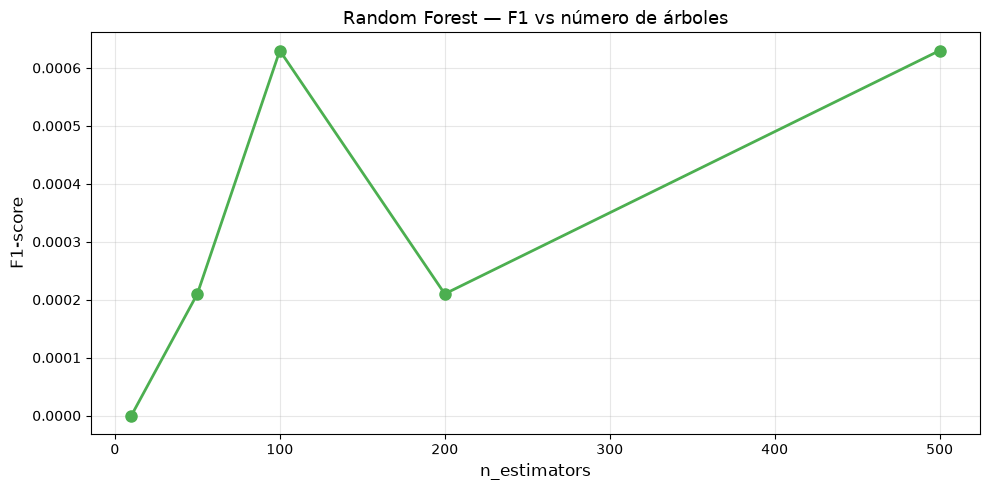


¿A partir de cuántos árboles el F1 deja de mejorar significativamente?


In [5]:
# Probar n_estimators = 10, 50, 100, 200, 500
n_estimators_list = [10, 50, 100, 200, 500]
f1_scores_rf = []

for n_est in n_estimators_list:
    rf_temp = RandomForestClassifier(n_estimators=n_est, max_depth=8, random_state=42, n_jobs=-1)
    rf_temp.fit(X_train_t1, y_train_t1)
    pred_temp = rf_temp.predict(X_test_t1)
    f1_temp = f1_score(y_test_t1, pred_temp, average="binary")
    f1_scores_rf.append(f1_temp)
    print(f"n_estimators={n_est:3d} → F1: {f1_temp:.4f}")

# Graficar
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(n_estimators_list, f1_scores_rf, marker='o', linewidth=2, markersize=8, color="#4CAF50")
ax.set_xlabel("n_estimators", fontsize=12)
ax.set_ylabel("F1-score", fontsize=12)
ax.set_title("Random Forest — F1 vs número de árboles", fontsize=13)
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"\n¿A partir de cuántos árboles el F1 deja de mejorar significativamente?")

**Respuesta.** En este problema el F1 no mejora con ningún número de árboles: queda entre 0,0000 y 0,0006 desde 10 hasta 500 árboles. Esas variaciones son ruido, de 1 a 3 aciertos de RURAL sobre 9.521. La curva plana no significa que el modelo converja rápido. Significa que siempre predice URBANO, y agregar árboles no cambia esa predicción.

En general, RF se estabiliza alrededor de 100 árboles. Más árboles reducen la varianza del promedio con retornos decrecientes y nunca empeoran el modelo, solo lo hacen más lento.

### 2.2 Gradient Boosting: ¿cuál learning_rate es mejor?

learning_rate=0.01 → F1: 0.0000


learning_rate=0.05 → F1: 0.0278


learning_rate=0.10 → F1: 0.0270


learning_rate=0.20 → F1: 0.0310


learning_rate=0.50 → F1: 0.0220


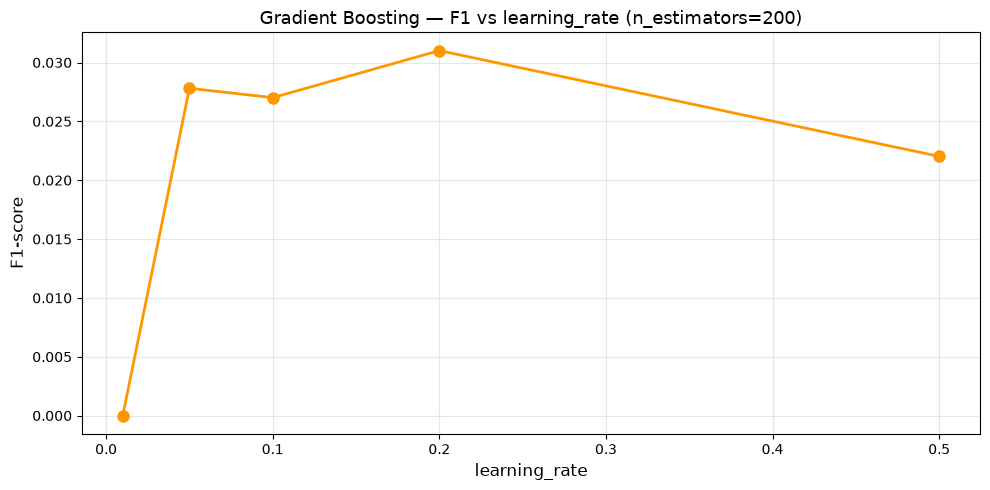


¿Cuál learning_rate dio el mejor F1? ¿Por qué un lr muy alto (0.5) podría empeorar?


In [6]:
# Probar learning_rate = 0.01, 0.05, 0.1, 0.2, 0.5 (n_estimators fijo=200)
lr_list = [0.01, 0.05, 0.1, 0.2, 0.5]
f1_scores_gb = []

for lr in lr_list:
    gb_temp = GradientBoostingClassifier(n_estimators=200, learning_rate=lr, max_depth=4, random_state=42)
    gb_temp.fit(X_train_t1, y_train_t1)
    pred_temp = gb_temp.predict(X_test_t1)
    f1_temp = f1_score(y_test_t1, pred_temp, average="binary")
    f1_scores_gb.append(f1_temp)
    print(f"learning_rate={lr:.2f} → F1: {f1_temp:.4f}")

# Graficar
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(lr_list, f1_scores_gb, marker='o', linewidth=2, markersize=8, color="#FF9800")
ax.set_xlabel("learning_rate", fontsize=12)
ax.set_ylabel("F1-score", fontsize=12)
ax.set_title("Gradient Boosting — F1 vs learning_rate (n_estimators=200)", fontsize=13)
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"\n¿Cuál learning_rate dio el mejor F1? ¿Por qué un lr muy alto (0.5) podría empeorar?")

**Respuesta.** El mejor F1 se obtuvo con `learning_rate=0.2` (0,0310), seguido de 0,05 (0,0278) y 0,1 (0,0270). Los extremos son los peores:
- **0,01 → F1 = 0.** Con 200 árboles × 0,01 el modelo apenas se aleja de la probabilidad inicial (13 % rural) y nunca supera el umbral de 0,5. Necesitaría muchos más árboles.
- **0,5 → F1 = 0,0220.** Cada árbol corrige los residuos con un paso demasiado grande: el modelo sobrecorrige y empieza a ajustar ruido. `learning_rate` y `n_estimators` se compensan: un lr bajo requiere más árboles y un lr alto sobreajusta antes.

Las diferencias son de pocas decenas de aciertos sobre 9.521 rurales: con ningún lr el modelo sirve para detectar colegios rurales.

---
## ⏸ Checkpoint del profesor (10 min)

**Discusión:**
1. ¿RF y GB coinciden en las features más importantes?
2. ¿Alguien obtuvo overfitting con el GB (mejor train que test)?
3. ¿Por qué RF se estabiliza rápido (>100 árboles) pero GB necesita ajustar learning_rate?

In [7]:
# Pregunta 2 del checkpoint: ¿hay overfitting? Comparar F1 en train vs test
for nombre, modelo in [("Random Forest", rf_t1), ("Gradient Boosting", gb_t1)]:
    f1_train = f1_score(y_train_t1, modelo.predict(X_train_t1), average="binary")
    f1_test = f1_score(y_test_t1, modelo.predict(X_test_t1), average="binary")
    print(f"{nombre:<18} → F1 train: {f1_train:.4f} | F1 test: {f1_test:.4f} | brecha: {f1_train - f1_test:+.4f}")

Random Forest      → F1 train: 0.0006 | F1 test: 0.0002 | brecha: +0.0004


Gradient Boosting  → F1 train: 0.0286 | F1 test: 0.0270 | brecha: +0.0016


**Respuestas del checkpoint**

1. **Features importantes:** coinciden en la principal (`FAMI_TIENEINTERNET_Si`) y en `COLE_NATURALEZA_OFICIAL`. Difieren en la tercera: computador en RF, jornada tarde en GB. El detalle está en la respuesta de la sección 1.3.
2. **Overfitting en GB:** no. La celda anterior muestra F1 train 0,0286 frente a test 0,0270 (brecha +0,0016); en RF, 0,0006 frente a 0,0002. Train y test son casi iguales porque las features solo forman 840 combinaciones y el modelo no tiene detalles que memorizar. El problema aquí es el contrario: subajuste, causado por el desbalance de clases y por features poco informativas.
3. **Por qué RF se estabiliza y GB necesita ajustar el lr:** RF entrena árboles independientes y los promedia. Agregar árboles solo reduce la varianza, así que desde unos 100 árboles la métrica se estabiliza y no hay forma de "pasarse". GB entrena árboles en secuencia, cada uno corrigiendo el error de los anteriores con un paso escalado por el learning rate. El resultado depende de la combinación `learning_rate × n_estimators`: si es muy baja no alcanza a aprender (lr 0,01 → F1 0) y si es muy alta sobrecorrige (lr 0,5 empeora). Por eso en GB se ajustan juntos, idealmente con early stopping.

---
## Tarea 3 (20 min) — MLP: ¿escalar cambia todo?

**Problema:** predecir `PUNT_MATEMATICAS` (regresión) usando features socioeconómicas.

### 3.1 Preparar datos

In [8]:
features_cat_t3 = ["COLE_NATURALEZA","COLE_AREA_UBICACION","COLE_JORNADA","COLE_BILINGUE",
                   "ESTU_GENERO","FAMI_TIENEINTERNET","FAMI_TIENECOMPUTADOR"]
df_t3 = df[features_cat_t3 + ["ESTRATO_NUM","PUNT_MATEMATICAS"]].dropna()

df_t3_enc = pd.get_dummies(df_t3, columns=features_cat_t3, drop_first=True, dtype=int)

X_t3 = df_t3_enc.drop("PUNT_MATEMATICAS", axis=1)
y_t3 = df_t3_enc["PUNT_MATEMATICAS"].astype(float)

X_train_t3, X_test_t3, y_train_t3, y_test_t3 = train_test_split(
    X_t3, y_t3, test_size=0.2, random_state=42
)

print(f"Train: {len(X_train_t3):,} | Test: {len(X_test_t3):,}")

Train: 294,060 | Test: 73,516


### 3.2 MLP sin escalar vs con escalar

In [9]:
# MLP SIN escalar
mlp_sin_t3 = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=300, random_state=42)
mlp_sin_t3.fit(X_train_t3, y_train_t3)
pred_sin_t3 = mlp_sin_t3.predict(X_test_t3)
rmse_sin = np.sqrt(mean_squared_error(y_test_t3, pred_sin_t3))
r2_sin = r2_score(y_test_t3, pred_sin_t3)

# MLP CON escalar
scaler_t3 = StandardScaler()
X_train_sc_t3 = scaler_t3.fit_transform(X_train_t3)
X_test_sc_t3 = scaler_t3.transform(X_test_t3)

mlp_con_t3 = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=300, random_state=42)
mlp_con_t3.fit(X_train_sc_t3, y_train_t3)
pred_con_t3 = mlp_con_t3.predict(X_test_sc_t3)
rmse_con = np.sqrt(mean_squared_error(y_test_t3, pred_con_t3))
r2_con = r2_score(y_test_t3, pred_con_t3)

print("=== Tarea 3: Predecir PUNT_MATEMATICAS (regresión) ===")
print(f"MLP SIN escalar → RMSE: {rmse_sin:.2f} | R²: {r2_sin:.4f}")
print(f"MLP CON escalar → RMSE: {rmse_con:.2f} | R²: {r2_con:.4f}")
print(f"\nMejora en R²: {(r2_con - r2_sin):.4f}")

=== Tarea 3: Predecir PUNT_MATEMATICAS (regresión) ===
MLP SIN escalar → RMSE: 10.68 | R²: 0.1970
MLP CON escalar → RMSE: 10.66 | R²: 0.1989

Mejora en R²: 0.0019


**Respuesta.** En este caso escalar casi no cambia nada: R² pasa de 0,1970 a 0,1989 (+0,0019) y el RMSE de 10,68 a 10,66. La razón es que las features ya están en rangos parecidos: todas son dummies 0/1, excepto `ESTRATO_NUM` (1 a 6).

Escalar es crítico en un MLP cuando las variables tienen escalas muy distintas (por ejemplo, ingresos en millones junto a edad en años), porque los gradientes quedan dominados por las variables grandes y el entrenamiento converge mal. Aquí ese problema no existe. Aun así, conviene escalar siempre antes de un MLP: no cuesta nada y elimina ese riesgo.

### 3.3 ¿Agregar más capas mejora?

In [10]:
# MLP más grande: (200, 100, 50)
mlp_grande_t3 = MLPRegressor(hidden_layer_sizes=(200, 100, 50), max_iter=300, random_state=42)
mlp_grande_t3.fit(X_train_sc_t3, y_train_t3)
pred_grande_t3 = mlp_grande_t3.predict(X_test_sc_t3)
rmse_grande = np.sqrt(mean_squared_error(y_test_t3, pred_grande_t3))
r2_grande = r2_score(y_test_t3, pred_grande_t3)

print(f"MLP (200,100,50) → RMSE: {rmse_grande:.2f} | R²: {r2_grande:.4f}")
print(f"\n¿Mejoró vs MLP (100,50)? Diferencia en R²: {(r2_grande - r2_con):.4f}")

MLP (200,100,50) → RMSE: 10.66 | R²: 0.1988

¿Mejoró vs MLP (100,50)? Diferencia en R²: -0.0001


**Pregunta:** ¿El MLP más grande mejoró significativamente? ¿Qué riesgo hay si aumentas demasiado la arquitectura?

**Respuesta.** No. El MLP (200, 100, 50) obtiene R² = 0,1988 frente a 0,1989 del (100, 50), una diferencia de −0,0001: ninguna mejora. El límite no está en la capacidad del modelo sino en la información de las features. Con 7 variables categóricas y el estrato, el MLP (100, 50) ya captura casi todo lo que explican: cerca del 20 % de la varianza del puntaje de matemáticas. El 80 % restante depende de variables que no están en el modelo.

Riesgos de aumentar demasiado la arquitectura:
- **Overfitting:** más parámetros permiten memorizar el ruido del train, sobre todo con pocos datos o sin regularización (`alpha`, `early_stopping`).
- **Costo:** más tiempo de entrenamiento y de inferencia sin ganancia.
- **Optimización más difícil:** las redes profundas son más sensibles a la inicialización y al learning rate, y pueden no converger dentro de `max_iter`.

---
## Tarea 4 (20 min) — Competencia: el mejor modelo de la clase

**Objetivo:** comparar TODOS los modelos del curso para predecir `DESEMP_INGLES` (5 clases).

### 4.1 Preparar datos

In [11]:
features_cat_t4 = ["COLE_NATURALEZA","COLE_AREA_UBICACION","COLE_JORNADA","COLE_BILINGUE",
                   "ESTU_GENERO","FAMI_TIENEINTERNET","FAMI_TIENECOMPUTADOR"]
df_t4 = df[features_cat_t4 + ["ESTRATO_NUM","DESEMP_INGLES"]].dropna()

df_t4_enc = pd.get_dummies(df_t4, columns=features_cat_t4, drop_first=True, dtype=int)

X_t4 = df_t4_enc.drop("DESEMP_INGLES", axis=1)
y_t4 = df_t4_enc["DESEMP_INGLES"]

X_train_t4, X_test_t4, y_train_t4, y_test_t4 = train_test_split(
    X_t4, y_t4, test_size=0.2, random_state=42, stratify=y_t4
)

# Escalar para KNN, SVM, MLP
scaler_t4 = StandardScaler()
X_train_sc_t4 = scaler_t4.fit_transform(X_train_t4)
X_test_sc_t4 = scaler_t4.transform(X_test_t4)

print(f"Train: {len(X_train_t4):,} | Test: {len(X_test_t4):,}")

Train: 293,785 | Test: 73,447


### 4.2 Entrenar 8 modelos

In [12]:
modelos_t4 = {
    "Logistic Regression": LogisticRegression(max_iter=500, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "SVM": SVC(kernel='rbf', random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=300, random_state=42),
}

# SVC escala entre O(n²) y O(n³) con el número de filas: con ~294k filas tardaría horas.
# Se entrena con una muestra estratificada de 20k filas y se evalúa en el test completo.
X_svm_t4, _, y_svm_t4, _ = train_test_split(
    X_train_sc_t4, y_train_t4, train_size=20_000, random_state=42, stratify=y_train_t4
)

resultados_t4 = []

for nombre, modelo in modelos_t4.items():
    if nombre == "SVM":
        modelo.fit(X_svm_t4, y_svm_t4)
        pred = modelo.predict(X_test_sc_t4)
    # Modelos que necesitan escalar
    elif nombre in ["Logistic Regression", "KNN", "SVM", "MLP"]:
        modelo.fit(X_train_sc_t4, y_train_t4)
        pred = modelo.predict(X_test_sc_t4)
    else:
        modelo.fit(X_train_t4, y_train_t4)
        pred = modelo.predict(X_test_t4)
    
    f1 = f1_score(y_test_t4, pred, average="weighted")
    acc = accuracy_score(y_test_t4, pred)
    resultados_t4.append({"Modelo": nombre, "F1_weighted": f1, "Accuracy": acc})

df_resultados_t4 = pd.DataFrame(resultados_t4).sort_values("F1_weighted", ascending=False).round(4)

print("=== COMPETENCIA: Todos los modelos del curso ===")
print("Problema: predecir DESEMP_INGLES (5 clases) con features socioeconómicas")
print(df_resultados_t4.to_string(index=False))

=== COMPETENCIA: Todos los modelos del curso ===
Problema: predecir DESEMP_INGLES (5 clases) con features socioeconómicas
             Modelo  F1_weighted  Accuracy
      Decision Tree       0.4489    0.4855
  Gradient Boosting       0.4434    0.4878
                MLP       0.4403    0.4875
                SVM       0.4362    0.4845
Logistic Regression       0.4238    0.4785
      Random Forest       0.4179    0.4840
                KNN       0.4068    0.4566


### 4.3 Visualizar: barplot de los 8 modelos

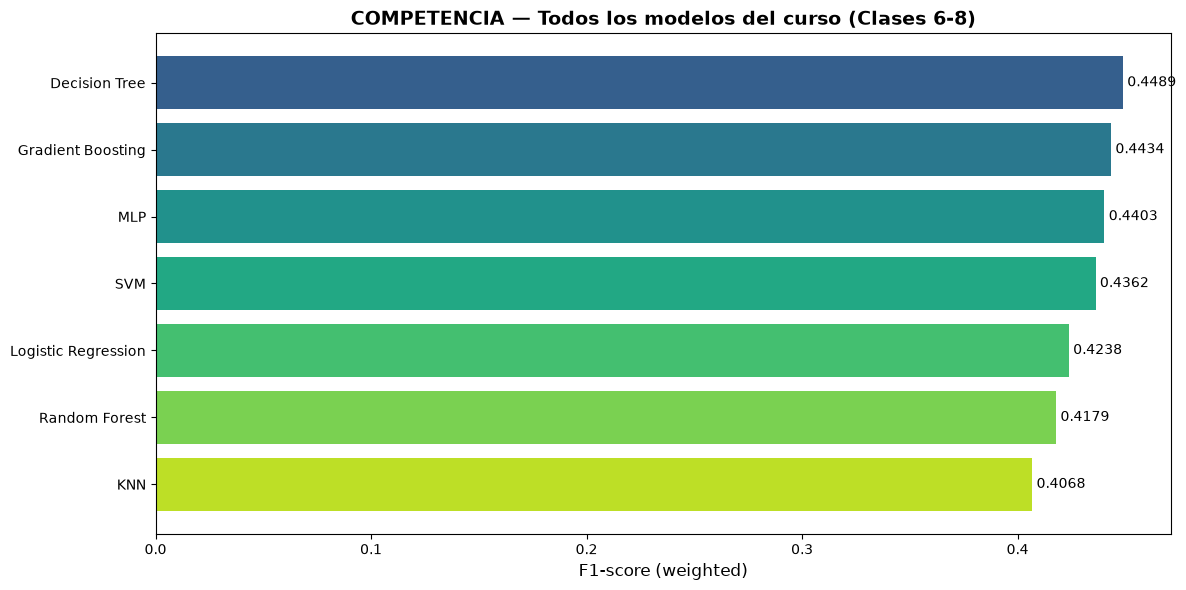


🏆 GANADOR: Decision Tree con F1=0.4489
❌ ÚLTIMO: KNN con F1=0.4068


In [13]:
fig, ax = plt.subplots(figsize=(12, 6))
colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(df_resultados_t4)))
ax.barh(df_resultados_t4["Modelo"], df_resultados_t4["F1_weighted"], color=colors)
ax.set_xlabel("F1-score (weighted)", fontsize=12)
ax.set_title("COMPETENCIA — Todos los modelos del curso (Clases 6-8)", fontsize=14, fontweight="bold")
ax.invert_yaxis()
for i, (modelo, f1) in enumerate(zip(df_resultados_t4["Modelo"], df_resultados_t4["F1_weighted"])):
    ax.text(f1 + 0.002, i, f"{f1:.4f}", va="center", fontsize=10)
plt.tight_layout(); plt.show()

print(f"\n🏆 GANADOR: {df_resultados_t4.iloc[0]['Modelo']} con F1={df_resultados_t4.iloc[0]['F1_weighted']:.4f}")
print(f"❌ ÚLTIMO: {df_resultados_t4.iloc[-1]['Modelo']} con F1={df_resultados_t4.iloc[-1]['F1_weighted']:.4f}")

**Preguntas finales:**
1. ¿Cuál modelo ganó? ¿Coincide con lo que esperabas de la pre-clase?
2. ¿Cuál es el peor modelo? ¿Por qué?
3. Si tuvieras que elegir UN modelo para producción, ¿cuál elegirías? (considera precisión + interpretabilidad + velocidad)

**Respuestas finales**

1. **¿Cuál ganó?** Decision Tree, con F1 weighted = 0,4489, seguido de Gradient Boosting (0,4434) y MLP (0,4403). Por accuracy gana Gradient Boosting (0,4878). No es lo esperado, porque los ensambles suelen superar a un árbol individual, pero aquí se explica por dos razones:
   - Las features solo forman 1.352 combinaciones distintas, así que un árbol de profundidad 8 ya captura las más frecuentes y a los ensambles les queda poca varianza que reducir.
   - Random Forest promedia 200 árboles, y eso empuja las predicciones hacia la clase mayoritaria: predice `A-` en el 73 % de los casos, frente al 60 % del árbol individual. Su accuracy es similar (0,4840), pero acierta menos en las clases minoritarias y el F1 weighted lo penaliza (0,4179).

   Las diferencias son pequeñas: todos los modelos quedan entre 0,41 y 0,45 de F1 y apenas entre 0,7 y 3,8 puntos de accuracy por encima del baseline de predecir siempre `A-` (0,4497).

2. **¿Cuál es el peor?** KNN (F1 = 0,4068, accuracy = 0,4566). Con solo 1.352 combinaciones de features entre 293.785 filas de train, el 98,6 % de los puntos de test tiene sus 15 vecinos a distancia 0, es decir, con features idénticas. Esos 15 vecinos se eligen por el orden de los empates, no por la distribución real de la clase en ese grupo. El voto termina siendo una muestra ruidosa de 15 estudiantes en lugar de la moda de miles. Además, la distancia euclidiana sobre dummies escaladas no tiene un significado natural.

3. **¿Cuál elegiría para producción?** Decision Tree:
   - **Precisión:** mejor F1 weighted (0,4489) y una accuracy a 0,2 puntos del mejor.
   - **Interpretabilidad:** sus reglas se pueden mostrar y explicar a un rector o a un funcionario de la Secretaría de Educación, algo que no ocurre con GB, MLP ni SVM.
   - **Velocidad:** entrena en segundos y predice al instante. GB tardó minutos en entrenar (un árbol por clase en cada iteración, en un solo núcleo) y SVM ni siquiera escala a 294k filas.

   Ningún modelo es bueno para esta tarea (F1 ≈ 0,45). La mejora en producción vendría de mejores features, por ejemplo los otros puntajes, el municipio o la educación de los padres, no de cambiar de algoritmo.

**Notas sobre la ejecución**
- La plantilla habla de 8 modelos pero define 7 clasificadores; `LinearRegression` (importada) es de regresión y no aplica a esta tarea.
- SVM se entrenó con una muestra estratificada de 20.000 filas y se evaluó sobre el test completo, porque `SVC` escala entre O(n²) y O(n³) y con 294k filas tardaría horas.
- El CSV tiene 128.843 filas duplicadas (26 % de la muestra). No cambia las conclusiones, porque con tan pocas combinaciones de features los vectores repetidos entre train y test son inevitables, pero conviene revisarlo antes de reutilizar este archivo.

---
## 🎯 Entrega

**Antes del jueves:** subir este notebook ejecutado (con outputs) a Moodle.

**Verifica:**
- [ ] Las 4 tareas están completas
- [ ] Todas las celdas están ejecutadas (con outputs visibles)
- [ ] Respondiste las preguntas de reflexión

**Siguiente clase:** cierre del P2/3 (40 min de trabajo grupal).